# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [1]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "....##.##.....",
    "#....#........",
    "##............",
    "#.........#...",
    "...#..........",
    "#.#..#........",
    "..............",
    "..#....#......",
    "..#....#.#....",
    "......#.......",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]


start = (0, 0)
goal = (9, 13)



rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [2]:

def get_neighbors(state):
    r, c = state

    moves = [
    (0, 1),   # prawo
    (0, -1),  # lewo
    (1, 0),   # dół
    (-1, 0),  # góra
    (-1, -1), # góra-lewo
    (-1, 1),  # góra-prawo
    (1, -1),  # dół-lewo
    (1, 1)    # dół-prawo
]
    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] != 1:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(0, 1), (1, 1)]



## 2. Wizualizacja problemu


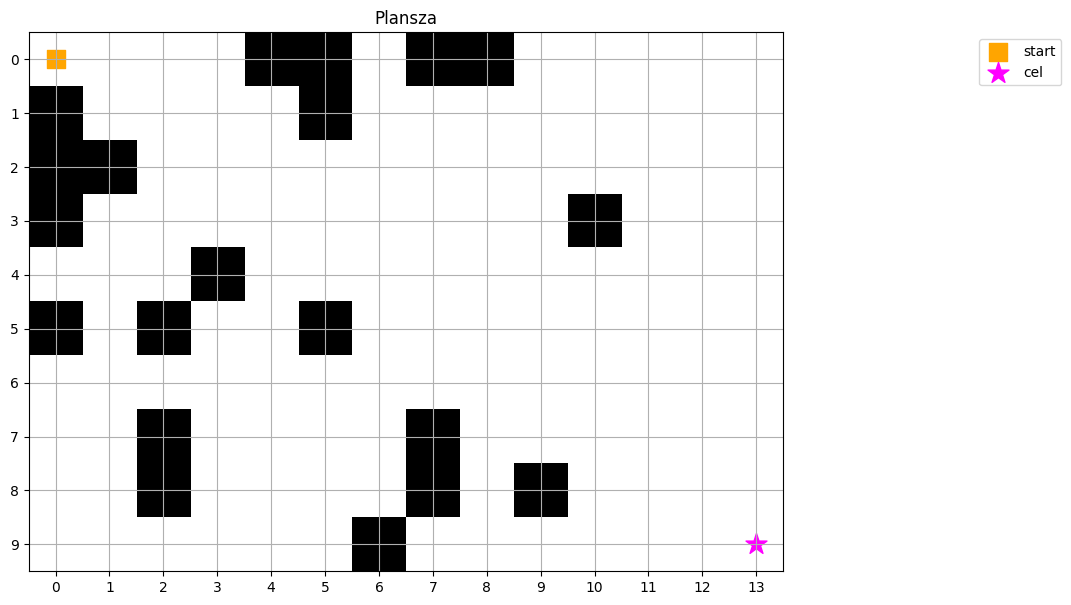

In [3]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]

        # kolor punktu = kolejność odwiedzin (ciemny - wcześnie, jasny - późno)
        plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                    s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o",
                 linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s",
                color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*",
                color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki: 13
BFS - odwiedzone stany: 120
BFS - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 4), (2, 5), (2, 6), (3, 7), (4, 8), (5, 9), (6, 10), (7, 11), (8, 12), (9, 13)]


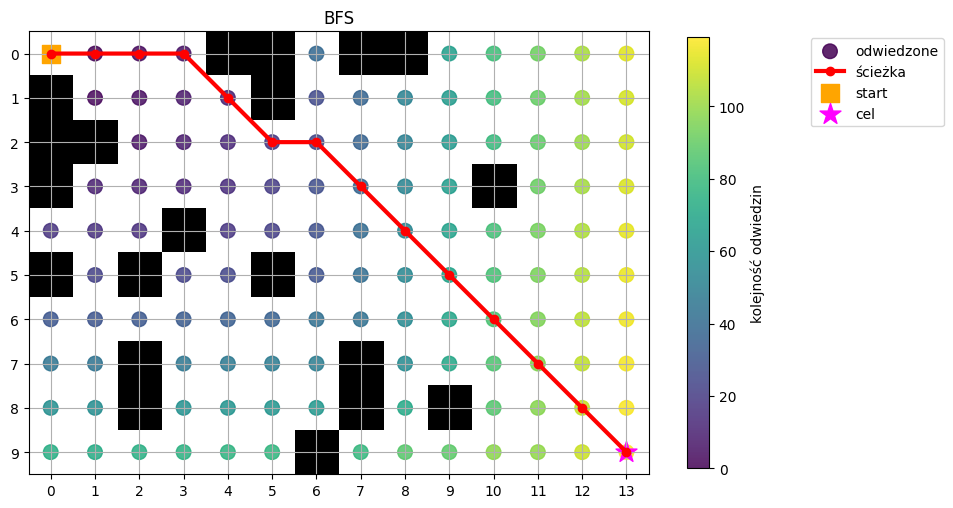

In [4]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")



### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?

  BFS używa kolejki, żeby sprawdzać najpierw najbliższe punkty.

2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?

  Bo najpierw sprawdza ścieżki z mniejszą liczbą kroków.
  
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?

  BFS będzie potrzebował dużo pamięci na przechowywanie odwiedzonych punktów.


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 15
DFS - odwiedzone stany: 16
DFS - ścieżka: [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 3), (6, 4), (7, 5), (8, 6), (9, 7), (8, 8), (9, 9), (8, 10), (9, 11), (8, 12), (9, 13)]


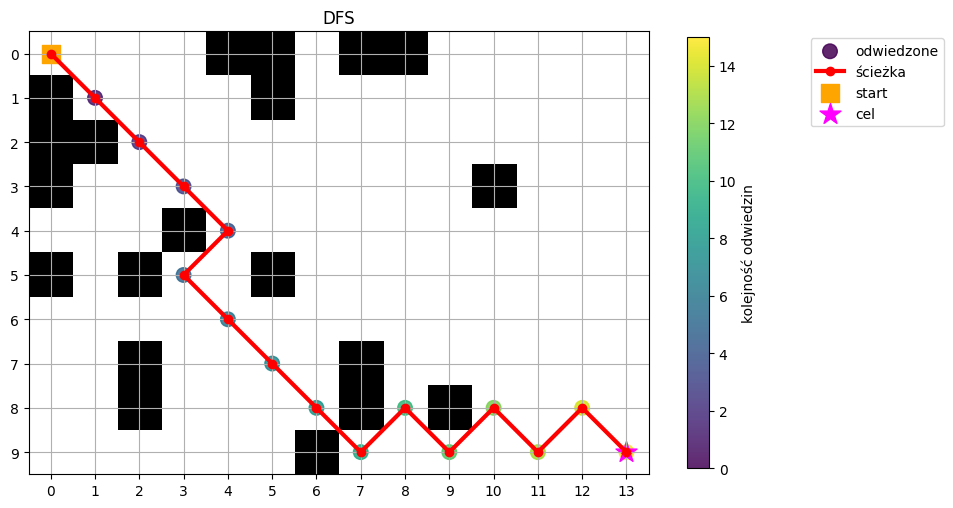

In [5]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [6]:
import math

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)

def h_chebyshev(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))

def h_zero(a, b):
    return 0

examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2),
        "Chebyshev =", round(h_chebyshev(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81 Chebyshev = 13
(4, 6) Manhattan = 12 Euclidean = 8.6 Chebyshev = 7
(7, 10) Manhattan = 5 Euclidean = 3.61 Chebyshev = 3
(9, 12) Manhattan = 1 Euclidean = 1.0 Chebyshev = 1



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 13
Greedy - odwiedzone stany: 14


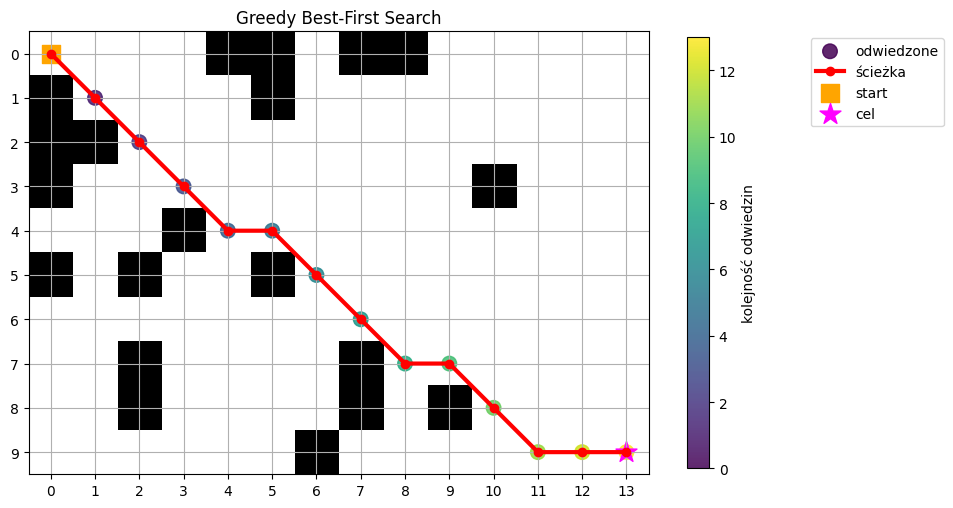

In [7]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


In [8]:
sand = {(0, 2), (1, 2), (1, 3)}
swamp = {(2, 3), (2, 4), (3, 4)}

for r, c in sand:
    if grid[r][c] == 0:
        grid[r][c] = 3

for r, c in swamp:
    if grid[r][c] == 0:
        grid[r][c] = 5

A* - koszt: 13
A* - odwiedzone stany: 14
A* - ścieżka: [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (4, 5), (5, 6), (6, 7), (7, 8), (7, 9), (8, 10), (9, 11), (9, 12), (9, 13)]


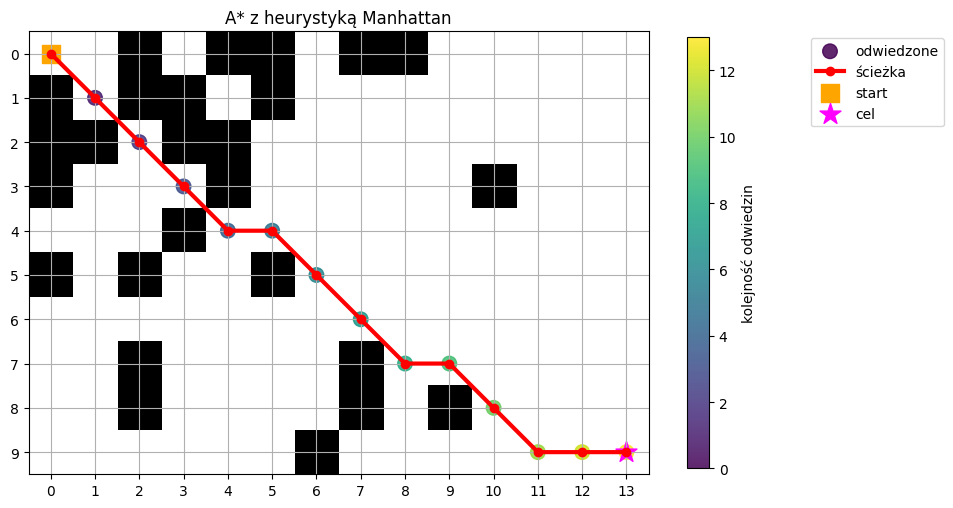

In [9]:
def terrain_cost(state):
    val = grid[state[0]][state[1]]
    if val == 3:
        return 3
    elif val == 5:
        return 5
    else:
        return 1


def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + terrain_cost(neighbor)

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [10]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")


Algorytm     Długość ścieżki    Odwiedzone stany
--------------------------------------------------
BFS          13                 120
DFS          15                 16
Greedy       13                 14
A*           13                 14



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [11]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 14
A* Euclidean - odwiedzone stany: 14



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [12]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))


A* z h=0 - odwiedzone stany: 120
BFS       - odwiedzone stany: 120



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 13
Odwiedzone stany: 14


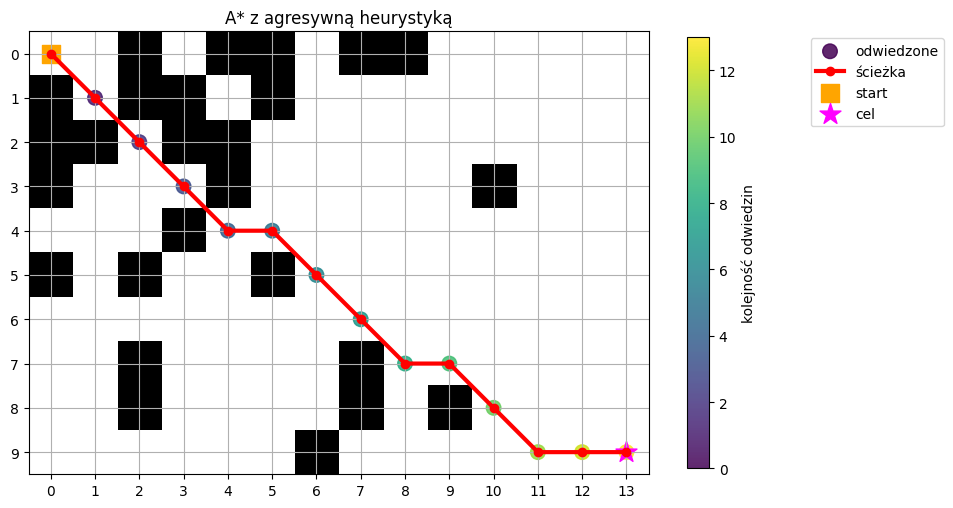

In [13]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)



# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

Przed zmianą:

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

- DFS - długość ścieżki: 42
- DFS - odwiedzone stany: 50

Po zmanie:


```
moves = [
        (0, 1),   # right
        (0, -1),  # left
        (1, 0),   # down
        (-1, 0),  # up
    ]
```
- DFS - długość ścieżki: 56
- DFS - odwiedzone stany: 88

Po zmianie kolejności ruchów algorytm DFS znalazł inną ścieżkę. Długość ścieżki zmieniła się z 42 na 56 kroków, a liczba odwiedzonych stanów wzrosła z 50 do 88. Dzieje się tak, ponieważ DFS korzysta ze stosu i kolejność ruchów wpływa na to, którą drogę algorytm wybiera najpierw. DFS nie gwarantuje znalezienia najkrótszej ścieżki.






---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

Przed zmianą:


```
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]
```


- BFS - długość ścieżki: 22
- BFS - odwiedzone stany: 102

- A* - koszt: 22
- A* - odwiedzone stany: 46

Po zmanie:


```
MAPA = [
    "....##.##.....",
    "#....#........",
    "##............",
    "#.........#...",
    "...#..........",
    "#.#..#........",
    "..............",
    "..#....#......",
    "..#....#.#....",
    "......#.......",
]
```


- BFS - długość ścieżki: 22
- BFS - odwiedzone stany: 120

- A* - koszt: 22
- A* - odwiedzone stany: 86

Algorytmy BFS i A* znalazły ścieżkę o długości 22. BFS odwiedził 120 stanów, a A* 86 stanów. Algorytm A* odwiedził o 34 stany mniej.



---

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def h_manh(a, b):
  return 0.5 * Manhattan(a, b)
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

Wszystkie heurystyki znalazły ścieżkę o takim samym koszcie równym 22. Manhattan odwiedziła 86 stanów, Euclidean 100 stanów, Chebyshev 104 stany, a A* z h(n) = 0 odwiedził 120 stanów. Najlepszy wynik uzyskała heurystyka Manhattan, ponieważ odwiedziła najmniej stanów. Heurystyka h(n) = 0 odwiedziła najwięcej stanów, ponieważ nie szacuje odległości do celu


---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

Dodałem ruchy po skosie:

```
 moves = [
    (0, 1),   # prawo
    (0, -1),  # lewo
    (1, 0),   # dół
    (-1, 0),  # góra
    (-1, -1), # góra-lewo
    (-1, 1),  # góra-prawo
    (1, -1),  # dół-lewo
    (1, 1)    # dół-prawo
]
```
1. Czy Manhattan nadal jest najlepszym wyborem?

W moim przypadku tak, jednym z najlepszych. Manhattan i Euclidean odwiedziły po 14 stanów, a Chebyshev 41 stanów.

2. Jaką heurystykę zastosować?

Na podstawie moich wyników najlepiej wybrać Manhattan lub Euclidean. Obie odwiedziły po 14 stanów i znalazły ścieżkę o koszcie 13.

3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy √2?

Ruch po przekątnej będzie kosztował więcej niż ruch prosty.

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

Nie. BFS znajduje najkrótszą ścieżkę pod względem liczby kroków, ale nie gwarantuje najniższego kosztu, gdy pola mają różne koszty przejścia.

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.

- g(n) oznacza koszt drogi, którą przeszliśmy od startu do obecnego punktu.
- h(n) to szacowany koszt drogi, którą musimy jeszcze pokonać do celu.
- Algorytm A* sumuje te wartości, aby wybrać najlepszą trasę.


# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [14]:
# Miejsce na rozwiązanie zadania 8-puzzle.

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne
1\. Co jest stanem w problemie wyszukiwania drogi?

Stan to aktualne położenie na mapie.

2\. Czym różni się BFS od DFS?

BFS szuka poziomami, a DFS idzie jedną drogą jak najdalej.

3\. Dlaczego BFS może potrzebować dużo pamięci?

Bo zapamiętuje dużo odwiedzonych punktów.

4\. Co oznacza \\(g(n)\\)?

Koszt drogi od startu do aktualnego punktu.

5\. Co oznacza \\(h(n)\\)?

Przewidywany koszt drogi do celu.

6\. Co oznacza \\(f(n)\\)?

Suma \\(g(n)\\) i \\(h(n)\\).

7\. Dlaczego heurystyka może przyspieszyć wyszukiwanie?

Bo pomaga kierować się w stronę celu.

8\. Co oznacza, że heurystyka jest dopuszczalna?

Nie zawyża rzeczywistego kosztu drogi do celu.

9\. Co się stanie w A, gdy \\(h(n)=0\\)?\*

A\* działa podobnie do algorytmu Dijkstry.

10\. Czy A zawsze jest szybszy od BFS?\*

Nie, to zależy od mapy i heurystyki.
